In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson, norm

In [3]:
data = np.loadtxt('../assets/1.1.4/Б06604_Осипов/эксперимент_2026-09-25_14-35-05.txt', comments='#', dtype=int)
total_points = len(data)
print(f"Загружено отсчетов: {total_points}\n")

intervals = [10, 20, 40, 80]


Загружено отсчетов: 4000



Группируем по 10
 Среднее <n>: 10.36 
 Стандартное отклонение: 3.075556473070787 
 Погрешность среднего: 0.003844445591338484 
 Интенсивность : 1.036 
 Погрешность интенсивности 0.0003844445591338484
Доля в пределах одной сигма: 68.5% (должно быть ~68.3%)
Доля в пределах двух сигма: 94.75% (должно быть ~95.5%)
Доля в пределах трех сигма: 99.75% (должно быть ~99.7%)

Группируем по 20
 Среднее <n>: 20.72 
 Стандартное отклонение: 4.388381187549251 
 Погрешность среднего: 0.010970952968873127 
 Интенсивность : 1.036 
 Погрешность интенсивности 0.0005485476484436563
Доля в пределах одной сигма: 70.0% (должно быть ~68.3%)
Доля в пределах двух сигма: 97.0% (должно быть ~95.5%)
Доля в пределах трех сигма: 100.0% (должно быть ~99.7%)

Группируем по 40
 Среднее <n>: 41.44 
 Стандартное отклонение: 6.00390445350929 
 Погрешность среднего: 0.03001952226754645 
 Интенсивность : 1.036 
 Погрешность интенсивности 0.0007504880566886613
Доля в пределах одной сигма: 63.0% (должно быть ~68.3%)
Доля в пр

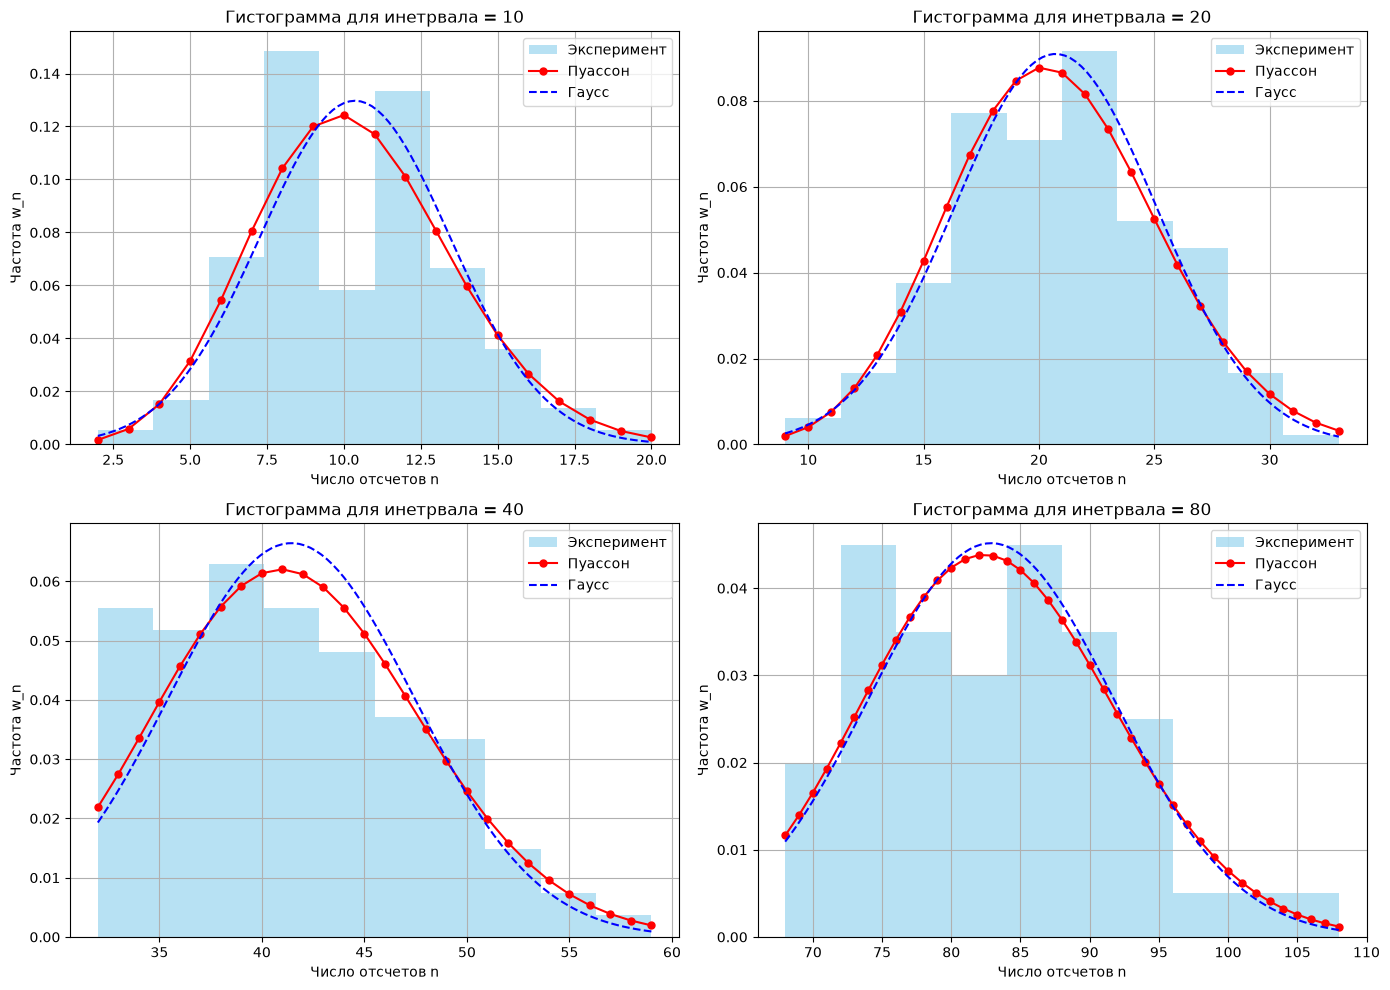

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, interval in enumerate(intervals):
    print(f"Группируем по {interval}")
    N = total_points // interval
    grouped_data = data[:N * interval].reshape((N, interval))
    sums = grouped_data.sum(axis=1)
    
    # п.16
    mean_n = np.mean(sums)                          
    std_n = np.std(sums, ddof=1)                    
    std_mean = std_n / N*(1/2)          
    intensive = mean_n / interval                            
    std_inten = std_mean / interval                        
    variance = np.var(sums, ddof=1)                 
    
    print(f" Среднее <n>: {mean_n} \n Стандартное отклонение: {std_n} \n Погрешность среднего: {std_mean} \n Интенсивность : {intensive} \n Погрешность интенсивности {std_inten}" )
    
    # 18. Проверка основного свойства распределения Пуассона <n> ≈ \u03c3_n^2
    #print(f"Проверка Пуассона: <n> = {mean_n:.3f}, \u03c3_n^2 = {variance:.3f}")
    
    # проверяем, какой процент значений попадает в каокй интервал (правило трёх сигм) (п.19)
    diffs = np.abs(sums - mean_n)
    sigma_1 = np.sum(diffs <= std_n) / N * 100
    sigma_2 = np.sum(diffs <= 2 * std_n) / N * 100
    sigma_3 = np.sum(diffs <= 3 * std_n) / N * 100
    
    print(f"Доля в пределах одной сигма: {sigma_1}% (должно быть ~68.3%)")
    print(f"Доля в пределах двух сигма: {sigma_2}% (должно быть ~95.5%)")
    print(f"Доля в пределах трех сигма: {sigma_3}% (должно быть ~99.7%)\n")

    # Гистограммы
    ax = axes[idx]
    #bins = np.arange(sums.min() - 0.5, sums.max() + 1.5, 1)
    # density=True нормализует гистограмму, чтобы площадь равнялась 1 (для сравнения с вероятностями)
    ax.hist(sums, density=True, alpha=0.6, color='skyblue', label='Эксперимент')
    
    # 17. Наложение теоретических распределений
    x_vals = np.arange(sums.min(), sums.max() + 1)
    
    # Распределение Пуассона
    poisson_pmf = poisson.pmf(x_vals, mu=mean_n)
    ax.plot(x_vals, poisson_pmf, 'ro-', markersize=5, label='Пуассон')
    
    # Распределение Гаусса
    x_gauss = np.linspace(sums.min(), sums.max(), 100)
    gauss_pdf = norm.pdf(x_gauss, loc=mean_n, scale=std_n)
    ax.plot(x_gauss, gauss_pdf, 'b--', label='Гаусс')
    
    ax.set_title(f'Гистограмма для инетрвала = {interval}')
    ax.set_xlabel('Число отсчетов n')
    ax.set_ylabel('Частота w_n')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()


Группируем по 10
 Среднее <n>: 10.36 
 Стандартное отклонение: 3.075556473070787 
 Погрешность среднего: 0.003844445591338484 
 Интенсивность : 1.036 
 Погрешность интенсивности 0.0003844445591338484
Доля в пределах одной сигма: 68.5% (должно быть ~68.3%)
Доля в пределах двух сигма: 94.75% (должно быть ~95.5%)
Доля в пределах трех сигма: 99.75% (должно быть ~99.7%)

Группируем по 20
 Среднее <n>: 20.72 
 Стандартное отклонение: 4.388381187549251 
 Погрешность среднего: 0.010970952968873127 
 Интенсивность : 1.036 
 Погрешность интенсивности 0.0005485476484436563
Доля в пределах одной сигма: 70.0% (должно быть ~68.3%)
Доля в пределах двух сигма: 97.0% (должно быть ~95.5%)
Доля в пределах трех сигма: 100.0% (должно быть ~99.7%)

Группируем по 40
 Среднее <n>: 41.44 
 Стандартное отклонение: 6.00390445350929 
 Погрешность среднего: 0.03001952226754645 
 Интенсивность : 1.036 
 Погрешность интенсивности 0.0007504880566886613
Доля в пределах одной сигма: 63.0% (должно быть ~68.3%)
Доля в пр

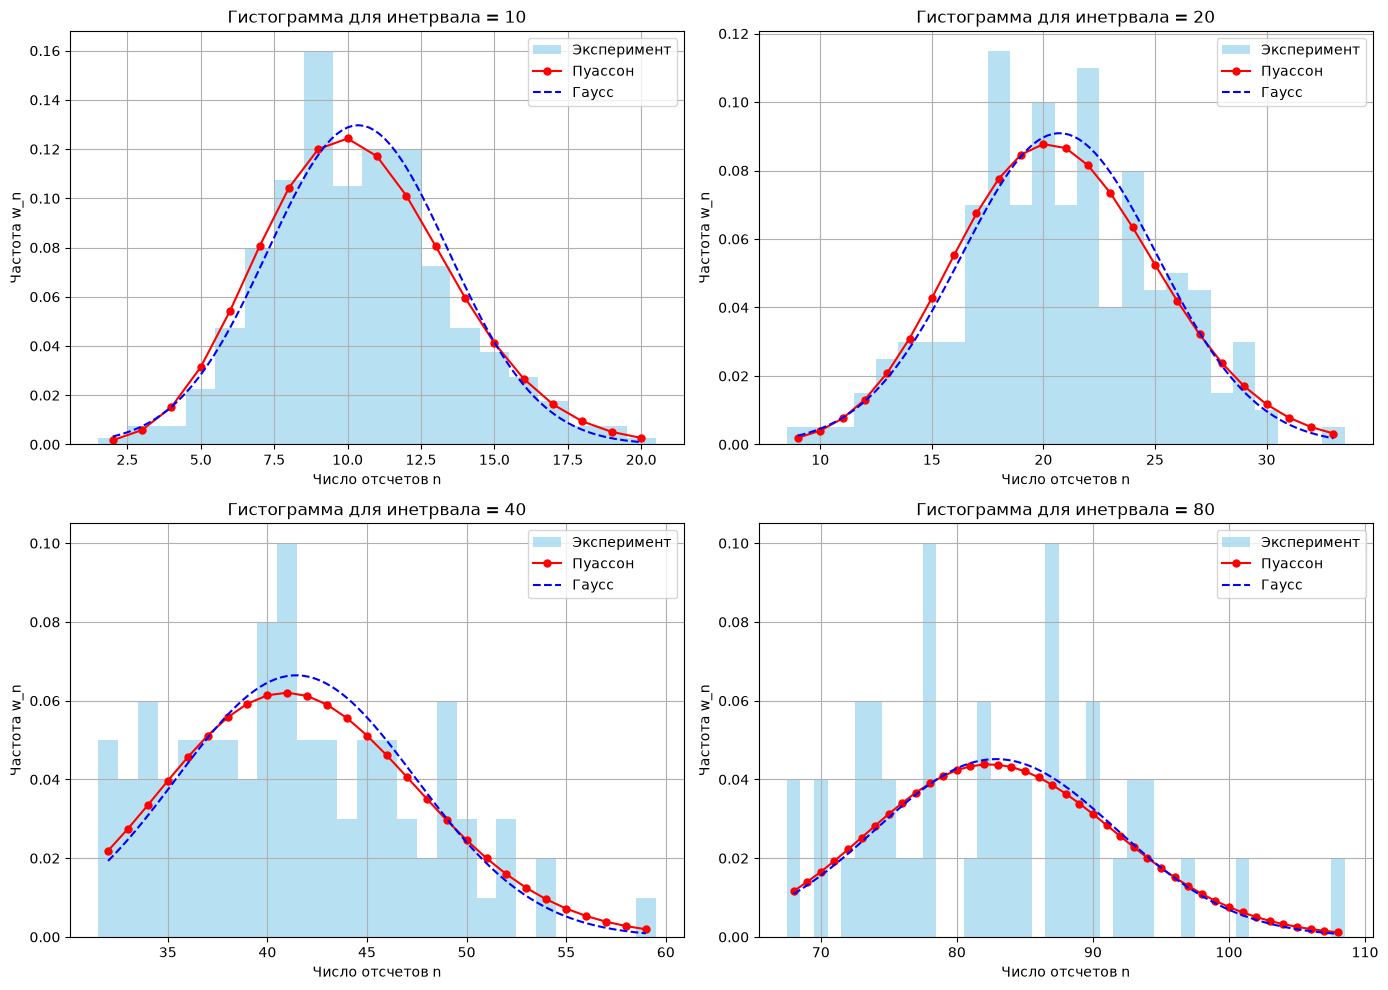

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, interval in enumerate(intervals):
    print(f"Группируем по {interval}")
    N = total_points // interval
    grouped_data = data[:N * interval].reshape((N, interval))
    sums = grouped_data.sum(axis=1)
    
    # п.16
    mean_n = np.mean(sums)                          
    std_n = np.std(sums, ddof=1)                    
    std_mean = std_n / N*(1/2)          
    intensive = mean_n / interval                            
    std_inten = std_mean / interval                        
    variance = np.var(sums, ddof=1)                 
    
    print(f" Среднее <n>: {mean_n} \n Стандартное отклонение: {std_n} \n Погрешность среднего: {std_mean} \n Интенсивность : {intensive} \n Погрешность интенсивности {std_inten}" )

    
    # проверяем, какой процент значений попадает в каокй интервал (правило трёх сигм) (п.19)
    diffs = np.abs(sums - mean_n)
    sigma_1 = np.sum(diffs <= std_n) / N * 100
    sigma_2 = np.sum(diffs <= 2 * std_n) / N * 100
    sigma_3 = np.sum(diffs <= 3 * std_n) / N * 100
    
    print(f"Доля в пределах одной сигма: {sigma_1}% (должно быть ~68.3%)")
    print(f"Доля в пределах двух сигма: {sigma_2}% (должно быть ~95.5%)")
    print(f"Доля в пределах трех сигма: {sigma_3}% (должно быть ~99.7%)\n")

    # Гистограммы
    ax = axes[idx]
    bins = np.arange(sums.min() - 0.5, sums.max() + 1.5, 1)
    ax.hist(sums, bins=bins, density=True, alpha=0.6, color='skyblue', label='Эксперимент')
    
    x_vals = np.arange(sums.min(), sums.max() + 1)
    
    # Распределение Пуассона
    poisson_pmf = poisson.pmf(x_vals, mu=mean_n)
    ax.plot(x_vals, poisson_pmf, 'ro-', markersize=5, label='Пуассон')
    
    # Распределение Гаусса
    x_gauss = np.linspace(sums.min(), sums.max(), 100)
    gauss_pdf = norm.pdf(x_gauss, loc=mean_n, scale=std_n)
    ax.plot(x_gauss, gauss_pdf, 'b--', label='Гаусс')
    
    ax.set_title(f'Гистограмма для инетрвала = {interval}')
    ax.set_xlabel('Число отсчетов n')
    ax.set_ylabel('Частота w_n')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()
